In [1]:
import numpy as np
import pandas as pd
import itertools
import scipy.stats
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import MultipleLocator
from scipy.stats.mstats import zscore
import matplotlib.gridspec as gridspec
import statsmodels.api as sm
from tqdm import tqdm

In [6]:
all_authors = pd.read_csv('E:/Data/SciSciNet/3Author/Author_name.csv.zip')
df = pd.read_csv('E:/Data/SciSciNet/3Author/Author_info.csv.zip')

In [6]:
Giorgio = all_authors[all_authors['Author_Name'] == 'Giorgio Parisi']
df1 = df[df['AuthorID'].isin(Giorgio['AuthorID'].values)]

In [ ]:
del df
del df1
aid = 2163147449

In [13]:
author2paper = pd.read_csv('E:/Data/SciSciNet/3Author/Paper_Author.csv.zip' , usecols=['PaperID', 'AuthorID'])
author2paper = author2paper.drop_duplicates().reset_index(drop=True)

In [19]:
pubs = author2paper[author2paper['AuthorID']==aid]

coauthordf = author2paper[author2paper['PaperID'].isin(pubs['PaperID'].unique())]
coauthordf = coauthordf.reset_index(drop=True)

In [23]:
paper2year = pd.read_csv('E:/Data/SciSciNet/Paper_year.csv.zip')

In [ ]:
coauthordf['Year'] = coauthordf['PaperID'].map(paper2year.set_index('PaperID')['Year'])
coauthordf['Focal_AID'] = aid
coauthordf['t'] = coauthordf['Year'] - 1970

In [29]:
coauthordf

,PaperID,AuthorID,Year,Focal_AID,t
0,51223950,2163147449,1998.0,2163147449,28.0
1,51223950,2611559540,1998.0,2163147449,28.0
2,51223950,2686679001,1998.0,2163147449,28.0
3,76011860,286216584,1998.0,2163147449,28.0
4,76011860,2103253634,1998.0,2163147449,28.0
...,...,...,...,...,...
3876,3215860989,2607280631,2021.0,2163147449,51.0
3877,3215860989,3111312582,2021.0,2163147449,51.0
3878,3216347758,1612371846,2020.0,2163147449,50.0
3879,3216347758,2064320820,2020.0,2163147449,50.0


# Load data

In [2]:
savepath = 'F:/A J YANG PAPER/2Under_review/HSSC Nobel repeat collaboration/Figs/Nobel2/'

In [3]:
def set_fig_(ax , xlabel=0, ylabel=0 , xlog=0, ylog=0, fontsize=16, iflegend=0, legendloc=2):
    if xlabel!=0:
        ax.set_xlabel(xlabel,size = fontsize)
    else:
        ax.set_xlabel('')
    if ylabel!=0:
        ax.set_ylabel(ylabel,size = fontsize)
    else:
        ax.set_ylabel('')
    if ylog:
        ax.set_yscale("log")
    if xlog:
        ax.set_xscale("log")
    if iflegend==1:
        ax.legend(frameon =False,fontsize = fontsize, loc=legendloc)
    if iflegend==2:
        ax.legend(frameon =False,fontsize = fontsize,ncol=1,bbox_to_anchor=(1, 0), loc=3, borderaxespad=0)
    ax.tick_params(axis='x',labelsize=fontsize)
    ax.tick_params(axis='y',labelsize=fontsize)
    plt.tick_params(axis='both', which='major', labelsize=16)
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)
    ax.spines["right"].set_linewidth(2)
    ax.spines["top"].set_linewidth(2)

In [32]:
df = pd.read_csv("E:/Data/SciSciNet/1Citation/Paper_nref.csv.zip")
coauthordf['Reference_Count'] = coauthordf['PaperID'].map(df.set_index('PaperID')['Reference_Count'])

df = pd.read_csv('E:/Data/SciSciNet/4Team/Paper_nau.csv.zip')
coauthordf['Team_Size'] = coauthordf['PaperID'].map(df.set_index('PaperID')['Team_Size'])

In [33]:
df = pd.read_csv("E:/Data/SciSciNet/1Citation/Paper_ncit.csv.zip")
coauthordf['cit_pct'] = coauthordf['PaperID'].map(df.set_index('PaperID')['cit_pct'])
coauthordf['cit_pct'] = coauthordf['cit_pct'].fillna(0)

df = pd.read_csv("E:/Data/SciSciNet/2Innovation/Paper_Disruption.csv.zip")
coauthordf['CD_pct'] = coauthordf['PaperID'].map(df.set_index('PaperID')['CD_pct'])

df = pd.read_csv("E:/Data/SciSciNet/2Innovation/Paper_Atypicality.csv.zip")
coauthordf['Novelty_pct'] = coauthordf['PaperID'].map(df.set_index('PaperID')['Novelty_pct'])

In [8]:
# winning_papers = pubs[pubs['is prize']=='YES']

# coauthordf['Nobel_paper'] = 0
# coauthordf.loc[coauthordf['PaperID'].isin(winning_papers['paperid'].values) , 'Nobel_paper'] = 1

# Illustration figure

In [34]:
data = coauthordf.groupby('AuthorID')['t'].min().reset_index()
data.columns = ['AuthorID','t_start']

maxyear = coauthordf.groupby('AuthorID')['t'].max().reset_index()
data['t_end'] = maxyear['t']

data['l'] = data['t_end'] - data['t_start']+1

n_k = coauthordf.groupby('AuthorID')['PaperID'].nunique().reset_index()
data['k'] = data['AuthorID'].map(n_k.set_index('AuthorID')['PaperID'])

In [35]:
avg_teamsize = coauthordf.groupby('AuthorID')['Team_Size'].mean().reset_index()
data['Team_Size'] = avg_teamsize['Team_Size']

avg_Novelty = coauthordf.groupby('AuthorID')['Novelty_pct'].mean().reset_index()
data['Novelty_pct'] = avg_Novelty['Novelty_pct']

avg_cit = coauthordf.groupby('AuthorID')['cit_pct'].mean().reset_index()
data['cit_pct'] = avg_cit['cit_pct']

avg_CD = coauthordf.groupby('AuthorID')['CD_pct'].mean().reset_index()
data['CD_pct'] = avg_CD['CD_pct']

In [36]:
data['l2'] = data['l'].apply(lambda x:x if x<10 else 10)
data = data.sort_values('t_start').reset_index(drop=True)
Prizeyear = 2021

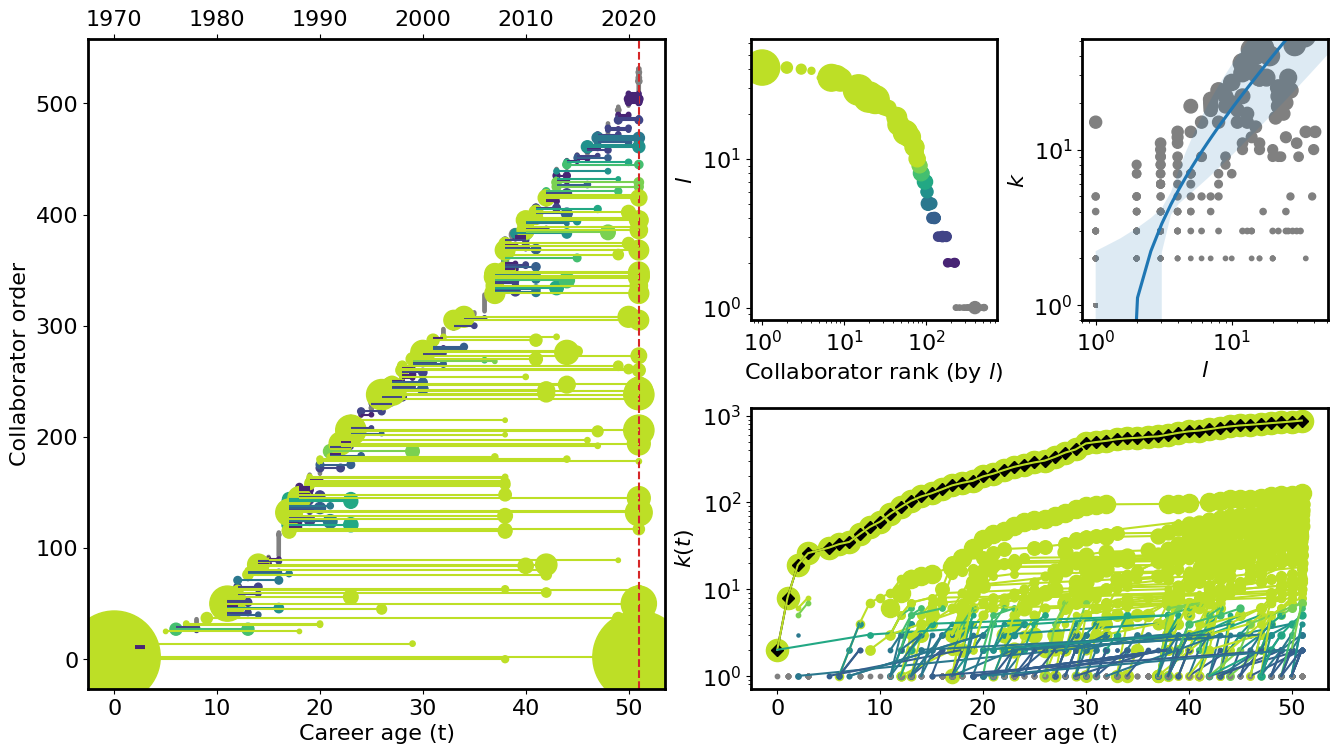

In [44]:
colors = sns.color_palette("viridis",9)
fig = plt.figure(figsize=(16 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, width_ratios=[1 ,1 , 1 , 1], height_ratios=[3, 3, 2], wspace=0.35, hspace=0.35)

ax = fig.add_subplot(gs[:2, :2])
plt.axvline(x = Prizeyear - coauthordf['Year'].min(), color='tab:red', linestyle='--')
plt.scatter(data[data['l2']==1]['t_start'].values , data[data['l2']==1].index , color = 'grey' , s=data[data['l2']==1]['k'].values*5)
for i in range(9):
    plt.scatter(data[data['l2']==i+2]['t_start'].values , data[data['l2']==i+2].index , color = colors[i] , s=data[data['l2']==i+2]['k'].values*5)
    plt.scatter(data[data['l2']==i+2]['t_end'].values , data[data['l2']==i+2].index , color = colors[i] , s=data[data['l2']==i+2]['k'].values*5)
    for j in range(len(data[data['l2']==i+2].index)):
        if data[data['l2']==i+2]['t_end'].values[j] != data[data['l2']==i+2]['t_start'].values[j]:
            plt.hlines(data[data['l2']==i+2].index[j] , data[data['l2']==i+2]['t_start'].values[j], data[data['l2']==i+2]['t_end'].values[j] , color = colors[i])
            # text = data[data['l2']==i+2]['k'].values[j]
            # if text >= 5:
            #     plt.text(data[data['l2']==i+2]['t_end'].values[j]+1 , data[data['l2']==i+2].index[j] , 'k = '+str(text) , horizontalalignment='center', verticalalignment='bottom',fontsize=14)
ax_top = ax.secondary_xaxis('top')
ax_top.set_ticks([0,10,20,30,40,50] , np.array(np.array([0,10,20,30,40,50]) + coauthordf['Year'].min()).astype(int))
ax_top.tick_params(axis='x', labelsize=16)
set_fig_(ax , xlabel='Career age (t)', ylabel='Collaborator order', xlog=0, iflegend=0)

ax = fig.add_subplot(gs[0, 2])
data_ = data.sort_values('l',ascending=False).reset_index(drop=True)
plt.scatter(data_[data_['l2']==1].index , data_[data_['l2']==1]['l'].values , color = 'grey' , s = data_[data_['l2']==1]['k'].values*5)
for i in range(9):
    plt.scatter(data_[data_['l2']==i+2].index , data_[data_['l2']==i+2]['l'].values , color = colors[i] , s =  data_[data_['l2']==i+2]['k'].values*5)
set_fig_(ax , xlabel='Collaborator rank (by $l$)', ylabel='$l$', xlog=1, ylog=1)

ax = fig.add_subplot(gs[1, 2:])
cu1_n_t = coauthordf.groupby('t')['PaperID'].nunique().reset_index()
cu1_n_t['n_cum'] = cu1_n_t['PaperID'].cumsum()
plt.plot(cu1_n_t['t'].values , cu1_n_t['n_cum'].values , 'k-' , marker = 'D')
for coauid in coauthordf['AuthorID'].unique():
    coauthordf_ = coauthordf[coauthordf['AuthorID']==coauid]
    if len (coauthordf_) > 1:
        cu1_n_t_ = coauthordf_.groupby('t')['PaperID'].count().reset_index()
        cu1_n_t_['n_cum'] = cu1_n_t_['PaperID'].cumsum()
        l = cu1_n_t_['n_cum'].max()
        plt.plot(cu1_n_t_['t'].values , cu1_n_t_['n_cum'].values , color=colors[l] if l<=8 else colors[-1])
        plt.scatter(cu1_n_t_['t'].values , cu1_n_t_['n_cum'].values , color=colors[l] if l<=8 else colors[-1] , s = len(cu1_n_t_)*5)
    else:
        plt.plot(coauthordf_['t'].values , [1] , color='grey')
        plt.scatter(coauthordf_['t'].values , [1] , color='grey' , s = 10)
set_fig_(ax , xlabel='Career age (t)', ylabel='$k (t)$', xlog=0, ylog=1)

# Add the other three subplots on the right side
ax = fig.add_subplot(gs[0, 3])
ax.scatter(data['l'].values , data['k'].values , color = 'grey' , s = data['k'].values*5)
sns.regplot(data , x='l' , y = 'k' , scatter=False)
plt.xlim(.8,51)
plt.ylim(.8,51)
set_fig_(ax , xlabel='$l$', ylabel='$k$', xlog=1, ylog=1, iflegend=0)
plt.savefig(savepath+"Illustration_main.svg",bbox_inches = 'tight')

## Legend

In [19]:
data['k'].max()

np.int64(11)

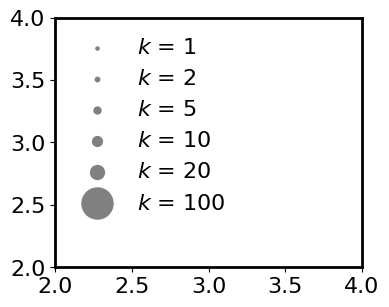

In [45]:
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)
ax = fig.add_subplot(gs[0])
for i in [1,2,5,10,20,100]:
    plt.scatter(1,1,color = 'grey',s=i*5,label = '$k$ = '+str(i))
plt.xlim(2,4)
plt.ylim(2,4)
set_fig_(ax , iflegend=1)
plt.savefig(savepath+"Illustration_legend1.svg",bbox_inches = 'tight')

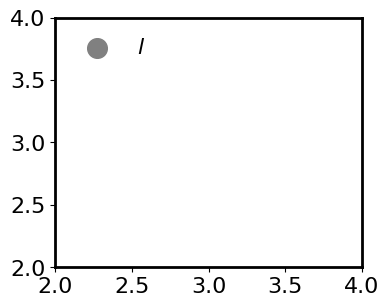

In [21]:
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)
ax = fig.add_subplot(gs[0])
plt.scatter(1,1,color = 'grey',s=i*5,label = '$l$')
plt.xlim(2,4)
plt.ylim(2,4)
set_fig_(ax , iflegend=1)
plt.savefig(savepath+"Illustration_legend2.svg",bbox_inches = 'tight')

In [35]:
colors = sns.color_palette("viridis",9)
grey = (0.5, 0.5, 0.5)  # RGB for grey
colors.insert(0, grey)

In [36]:
colors

[(0.5, 0.5, 0.5),
 (0.282623, 0.140926, 0.457517),
 (0.253935, 0.265254, 0.529983),
 (0.206756, 0.371758, 0.553117),
 (0.163625, 0.471133, 0.558148),
 (0.127568, 0.566949, 0.550556),
 (0.134692, 0.658636, 0.517649),
 (0.266941, 0.748751, 0.440573),
 (0.477504, 0.821444, 0.318195),
 (0.741388, 0.873449, 0.149561)]

## Calculation

In [140]:
for i in laureates['Author_Name'].values:
    if 'Ander' in i:
        print(i)

Philip W. Anderson
Carl D. Anderson


In [141]:
laureates[laureates['Author_Name'] == 'Philip W. Anderson']

,AuthorID,Author_Name,H-index,Productivity,Average_C10,Average_LogC10,FirstYear,LastYear,Prize year,Field,SimpleName
138,2108077945,Philip W. Anderson,70,278,226.434783,2.916646,1949.0,2021.0,1977,Physics,P Anderson


In [104]:
# coauthordflst = []
# for auid in tqdm(laureates['AuthorID'].values):
#     paper1 = au2p.loc[au2p['AuthorID']==auid , 'PaperID'].values
#     coauthor1 = au2p[au2p['PaperID'].isin(paper1)].reset_index(drop=True)
#     coauthordf = coauthor1[coauthor1['AuthorID']!=auid].reset_index(drop=True)
#     coauthordf['Year'] = coauthordf['PaperID'].map(PaperY.set_index('PaperID')['Year'])
#     coauthordf['t_start'] = coauthordf['Year'] - coauthordf['Year'].min()
#     coauthordf['Focal_AID'] = auid
#     coauthordflst.append(coauthordf)

# coauthordf = pd.concat(coauthordflst)
# coauthordf.to_csv(r"E:\Data\SciSciNet\Paper\Nobel\Nobel Laureates\375NobelLaureatesCoauthors.csv.zip" , index = False)

100%|██████████████████████████████████████████████████████████████████████████████| 375/375 [3:34:39<00:00, 34.35s/it]


# Distribution (length and n k) fig

In [4]:
coauthordf = pd.read_csv(r"E:\Data\SciSciNet\Others\Nobel\Nobel Laureates\NobelCoauthors_2024.csv.zip")

In [11]:
laureates = pd.read_csv(r"E:\Data\SciSciNet\Others\Nobel\Nobel Laureates\423NobelLaureates_2024.csv.zip")
df = pd.read_csv('E:/Data/SciSciNet/3Author/Author_beginyear.csv.zip')
laureates['FirstYear'] = laureates['AuthorID'].map(df.set_index('AuthorID')['FirstYear'])
laureates['Prize t'] = laureates['Prize year'] - laureates['FirstYear']

In [7]:
data = coauthordf.groupby(['Focal_AID','AuthorID'])['t'].min().reset_index()
data.columns = ['Focal_AID','AuthorID','t_start']

maxyear = coauthordf.groupby(['Focal_AID','AuthorID'])['t'].max().reset_index()
data['t_end'] = maxyear['t']
data['l'] = data['t_end'] - data['t_start']+1

n_k = coauthordf.groupby(['Focal_AID','AuthorID'])['PaperID'].nunique().reset_index()
data['k'] = n_k['PaperID']

data['Field'] = data['Focal_AID'].map(laureates.set_index('AuthorID')['Field'])
data = data[data['k']>1].reset_index(drop=True)

In [8]:
data['Avg_l'] = data.groupby('Focal_AID')['l'].transform('mean')
data['Avg_n_k'] = data.groupby('Focal_AID')['k'].transform('mean')
data['R_l'] = data['l'] / data['Avg_l']
data['R_n_k'] = data['k'] / data['Avg_n_k']

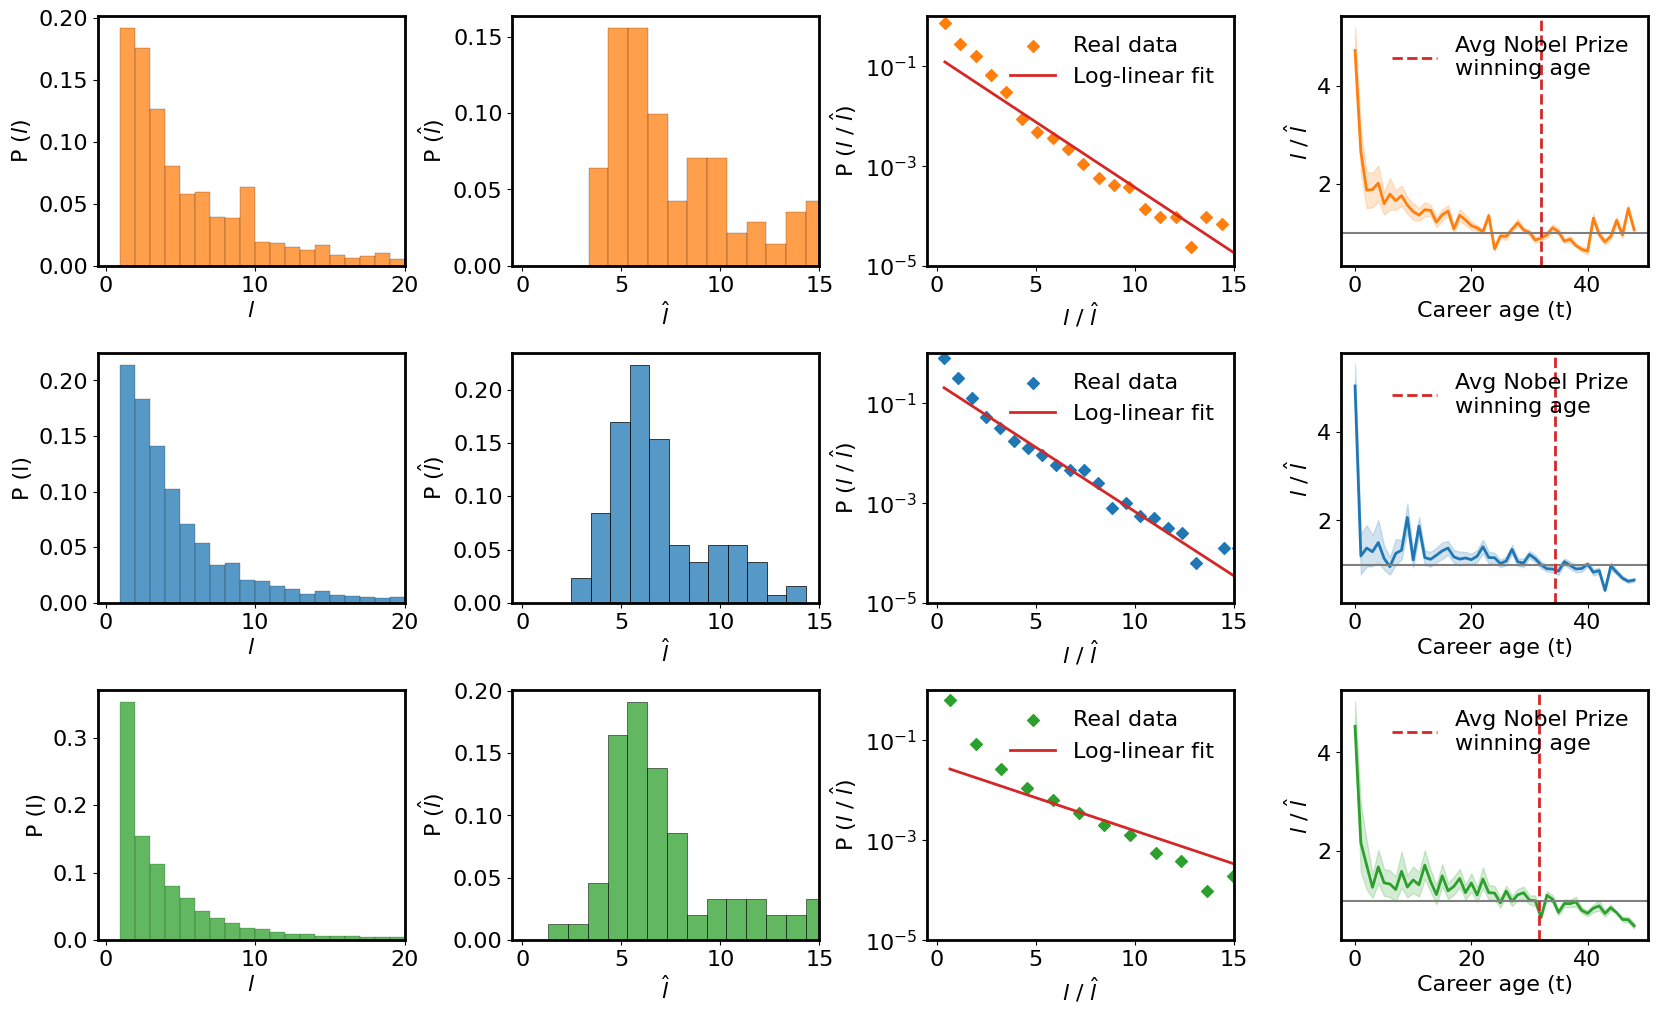

In [12]:
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)

data_ = data[data['Field']=='Physics']
ax = fig.add_subplot(gs[0])
sns.histplot(data_['l'].values, binwidth=1, stat='proportion' , color = 'tab:orange')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$l$', ylabel='P ($l$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[1])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_l'].values, binwidth=1, stat='proportion' , color = 'tab:orange')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{l}$', ylabel=r'P ($\hat{l}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[2])
hist_values, bin_edges = np.histogram(data_['R_l'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:orange', marker='D', label='Real data')
log_hist_values = np.log10(hist_values + 1e-6)  # Avoid log of zero by adding a small constant
regression = scipy.stats.linregress(bin_centers, log_hist_values)
fitted_line = 10 ** (bin_centers * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-linear fit')
plt.ylim(.00001 , 1.01)
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$l$ / $\hat{l}$', ylabel=r'P ($l$ / $\hat{l}$)', xlog=0, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[3])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_l' , lw = 2 , color = 'tab:orange')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Physics' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$l$ / $\hat{l}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 1)

data_ = data[data['Field']=='Chemistry']
ax = fig.add_subplot(gs[4])
sns.histplot(data_['l'].values, binwidth=1, stat='proportion' , color = 'tab:blue')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$l$', ylabel='P (l)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[5])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_l'].values, binwidth=1, stat='proportion' , color = 'tab:blue')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{l}$', ylabel=r'P ($\hat{l}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[6])
hist_values, bin_edges = np.histogram(data_['R_l'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:blue', marker='D', label='Real data')
log_hist_values = np.log10(hist_values + 1e-6)  # Avoid log of zero by adding a small constant
regression = scipy.stats.linregress(bin_centers, log_hist_values)
fitted_line = 10 ** (bin_centers * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-linear fit')
plt.ylim(.00001 , 1.01)
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$l$ / $\hat{l}$', ylabel=r'P ($l$ / $\hat{l}$)', xlog=0, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[7])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_l' , lw = 2 , color = 'tab:blue')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Chemistry' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$l$ / $\hat{l}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 1)

data_ = data[data['Field']=='Medicine']
ax = fig.add_subplot(gs[8])
sns.histplot(data_['l'].values, binwidth=1, stat='proportion' , color = 'tab:green')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$l$', ylabel='P (l)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[9])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_l'].values, binwidth=1, stat='proportion' , color = 'tab:green')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{l}$', ylabel=r'P ($\hat{l}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[10])
hist_values, bin_edges = np.histogram(data_['R_l'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:green', marker='D', label='Real data')
log_hist_values = np.log10(hist_values + 1e-6)  # Avoid log of zero by adding a small constant
regression = scipy.stats.linregress(bin_centers, log_hist_values)
fitted_line = 10 ** (bin_centers * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-linear fit')
plt.ylim(.00001 , 1.01)
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$l$ / $\hat{l}$', ylabel=r'P ($l$ / $\hat{l}$)', xlog=0, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[11])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_l' , lw = 2 , color = 'tab:green')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Medicine' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$l$ / $\hat{l}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 1)
plt.savefig(savepath+"Distribution_clength.svg",bbox_inches = 'tight')

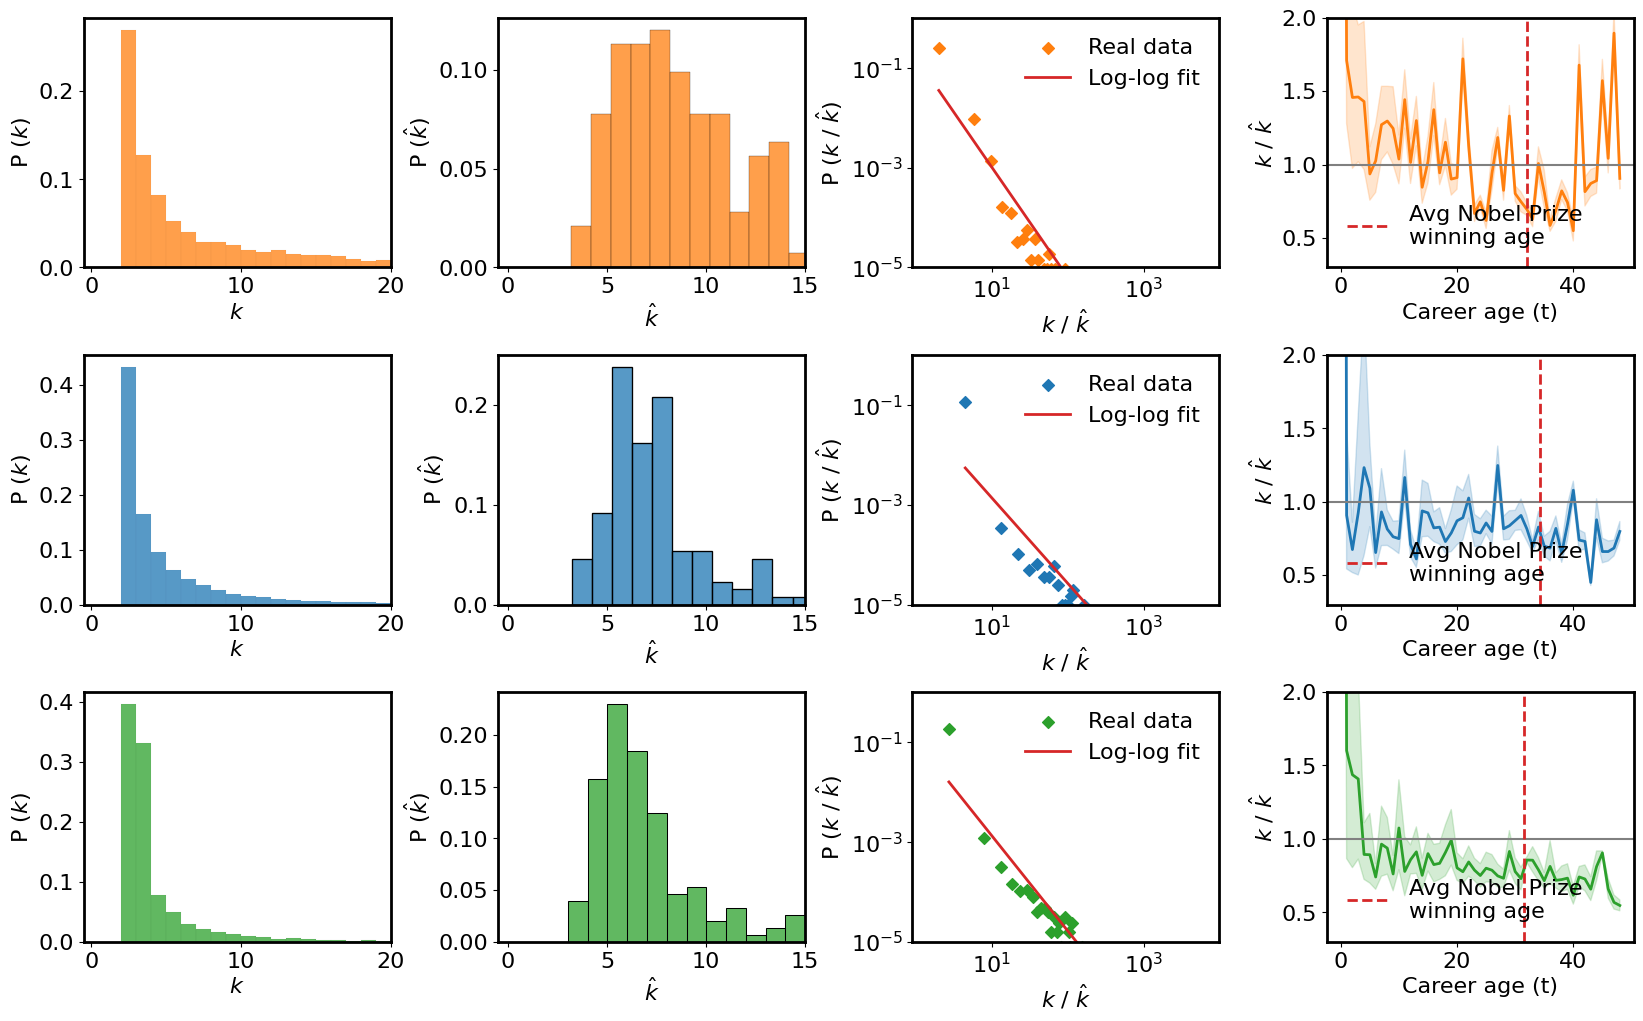

In [13]:
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)

data_ = data[data['Field']=='Physics']
ax = fig.add_subplot(gs[0])
sns.histplot(data_['k'].values, binwidth=1, stat='proportion' , color = 'tab:orange')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$k$', ylabel='P ($k$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[1])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_n_k'].values, binwidth=1, stat='proportion' , color = 'tab:orange')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{k}$', ylabel=r'P ($\hat{k}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[2])
hist_values, bin_edges = np.histogram(data_['R_n_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:orange', marker='D', label='Real data')
regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-log fit')
plt.ylim(.00001 , 1.01)
plt.xlim(.9,10001)
set_fig_(ax , xlabel=r'$k$ / $\hat{k}$', ylabel=r'P ($k$ / $\hat{k}$)', xlog=1, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[3])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_n_k' , lw = 2 , color = 'tab:orange')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Physics' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
plt.ylim(0.3 , 2)
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$k$ / $\hat{k}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 3)

data_ = data[data['Field']=='Chemistry']
ax = fig.add_subplot(gs[4])
sns.histplot(data_['k'].values, binwidth=1, stat='proportion' , color = 'tab:blue')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$k$', ylabel='P ($k$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[5])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_n_k'].values, binwidth=1, stat='proportion' , color = 'tab:blue')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{k}$', ylabel=r'P ($\hat{k}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[6])
hist_values, bin_edges = np.histogram(data_['R_n_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:blue', marker='D', label='Real data')
regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-log fit')
plt.ylim(.00001 , 1.01)
plt.xlim(.9,10001)
set_fig_(ax , xlabel=r'$k$ / $\hat{k}$', ylabel=r'P ($k$ / $\hat{k}$)', xlog=1, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[7])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_n_k' , lw = 2 , color = 'tab:blue')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Chemistry' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
plt.ylim(0.3 , 2)
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$k$ / $\hat{k}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 3)

data_ = data[data['Field']=='Medicine']
ax = fig.add_subplot(gs[8])
sns.histplot(data_['k'].values, binwidth=1, stat='proportion' , color = 'tab:green')
plt.xlim(-.5,20)
set_fig_(ax , xlabel='$k$', ylabel='P ($k$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[9])
sns.histplot(data_.drop_duplicates('Focal_AID')['Avg_n_k'].values, binwidth=1, stat='proportion' , color = 'tab:green')
plt.xlim(-.5,15)
set_fig_(ax , xlabel=r'$\hat{k}$', ylabel=r'P ($\hat{k}$)', xlog=0, ylog=0)

ax = fig.add_subplot(gs[10])
hist_values, bin_edges = np.histogram(data_['R_n_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:green', marker='D', label='Real data')
regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='tab:red', linestyle='-', lw = 2, label='Log-log fit')
plt.ylim(.00001 , 1.01)
plt.xlim(.9,10001)
set_fig_(ax , xlabel=r'$k$ / $\hat{k}$', ylabel=r'P ($k$ / $\hat{k}$)', xlog=1, ylog=1 , iflegend = 1 , legendloc= 1)

ax = fig.add_subplot(gs[11])
sns.lineplot(data_[data_['t_start']<=48] , x = 't_start' , y = 'R_n_k' , lw = 2 , color = 'tab:green')
plt.axhline(1 , c = 'grey' , ls='-')
plt.axvline(laureates.loc[laureates['Field']=='Medicine' , 'Prize t'].mean() , c = 'tab:red' , lw = 2 , ls='--' , label = 'Avg Nobel Prize\nwinning age')
set_fig_(ax , xlabel=r'Career age (t)', ylabel=r'$k$ / $\hat{k}$', xlog=0, ylog=0 , iflegend = 1 , legendloc= 3)
plt.ylim(0.3 , 2)
plt.savefig(savepath+"Distribution_ck.svg",bbox_inches = 'tight')

# Collaboration Life Cycle

In [18]:
data = coauthordf.groupby(['Focal_AID','AuthorID'])['t_start'].min().reset_index()
maxyear = coauthordf.groupby(['Focal_AID','AuthorID'])['t_start'].max().reset_index()
data['t_end'] = maxyear['t_start']
data['l'] = data['t_end'] - data['t_start']+1

n_k = coauthordf.groupby(['Focal_AID','AuthorID'])['PaperID'].nunique().reset_index()
data['k'] = n_k['PaperID']

data['Field'] = data['Focal_AID'].map(laureates.set_index('AuthorID')['Field'])
data = data[data['k']>1].reset_index(drop=True)

In [19]:
data['Avg_l'] = data.groupby('Focal_AID')['l'].transform('mean')
data['Avg_n_k'] = data.groupby('Focal_AID')['k'].transform('mean')
data['R_l'] = data['l'] / data['Avg_l']
data['R_n_k'] = data['k'] / data['Avg_n_k']

In [50]:
yn_k = coauthordf.groupby(['Focal_AID', 'AuthorID' , 't_start'])['PaperID'].nunique().reset_index()
yn_k.columns = ['Focal_AID', 'AuthorID' , 't_', 'delta_k']
yn_k = yn_k.merge(data[['Focal_AID', 'AuthorID', 't_start', 'k']] , on = ['Focal_AID', 'AuthorID'])
yn_k['tau'] = yn_k['t_'] - yn_k['t_start']
yn_k['Field'] =yn_k['Focal_AID'].map(laureates.set_index('AuthorID')['Field'])
yn_k['cum_k'] = yn_k.groupby(['Focal_AID','AuthorID'])['delta_k'].cumsum()

In [51]:
yn_k

,Focal_AID,AuthorID,t_,delta_repeat,t,n_repeat,tau,Field,cum_repeat
0,8397825,1452879184,16.0,1,16.0,27,0.0,Medicine,1
1,8397825,1452879184,18.0,8,16.0,27,2.0,Medicine,9
2,8397825,1452879184,21.0,1,16.0,27,5.0,Medicine,10
3,8397825,1452879184,23.0,1,16.0,27,7.0,Medicine,11
4,8397825,1452879184,24.0,1,16.0,27,8.0,Medicine,12
...,...,...,...,...,...,...,...,...,...
173653,3211647818,3117590862,6.0,1,3.0,8,3.0,Physics,4
173654,3211647818,3117590862,7.0,1,3.0,8,4.0,Physics,5
173655,3211647818,3117590862,10.0,2,3.0,8,7.0,Physics,7
173656,3211647818,3117590862,11.0,1,3.0,8,8.0,Physics,8


In [41]:
# def get_tbin(x):
#     if x<10:
#         return '0-9'
#     elif x<20:
#         return '10-19'
#     elif x<30:
#         return '20-29'
#     else:
#         return '30+'
def get_t_type(x):
    if x<30:
        return 'Early collaborators'
    else:
        return 'Later collaborators'
yn_k['tbin'] = yn_k['t_start'].apply(get_t_type)

In [42]:
yn_k_ = yn_k[yn_k['Field'] == 'Physics']

<Axes: xlabel='tau', ylabel='delta_repeat'>

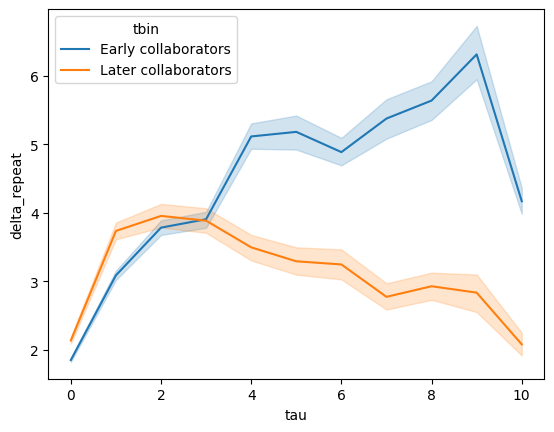

In [53]:
sns.lineplot(yn_k_[yn_k_['tau']<=10] , x = 'tau' , y = 'delta_k' , hue = 'tbin', markers=['D'])

# Relationship with citation/innovation

In [38]:
avg_teamsize = coauthordf.groupby(['Focal_AID','AuthorID'])['Team_Size'].mean().reset_index()
data['Team_Size'] = avg_teamsize['Team_Size']

avg_Novelty = coauthordf.groupby(['Focal_AID','AuthorID'])['Novelty_pct'].mean().reset_index()
data['Novelty_pct'] = avg_Novelty['Novelty_pct']

avg_cit = coauthordf.groupby(['Focal_AID','AuthorID'])['cit_pct'].mean().reset_index()
data['cit_pct'] = avg_cit['cit_pct']

avg_CD = coauthordf.groupby(['Focal_AID','AuthorID'])['CD_pct'].mean().reset_index()
data['CD_pct'] = avg_CD['CD_pct']

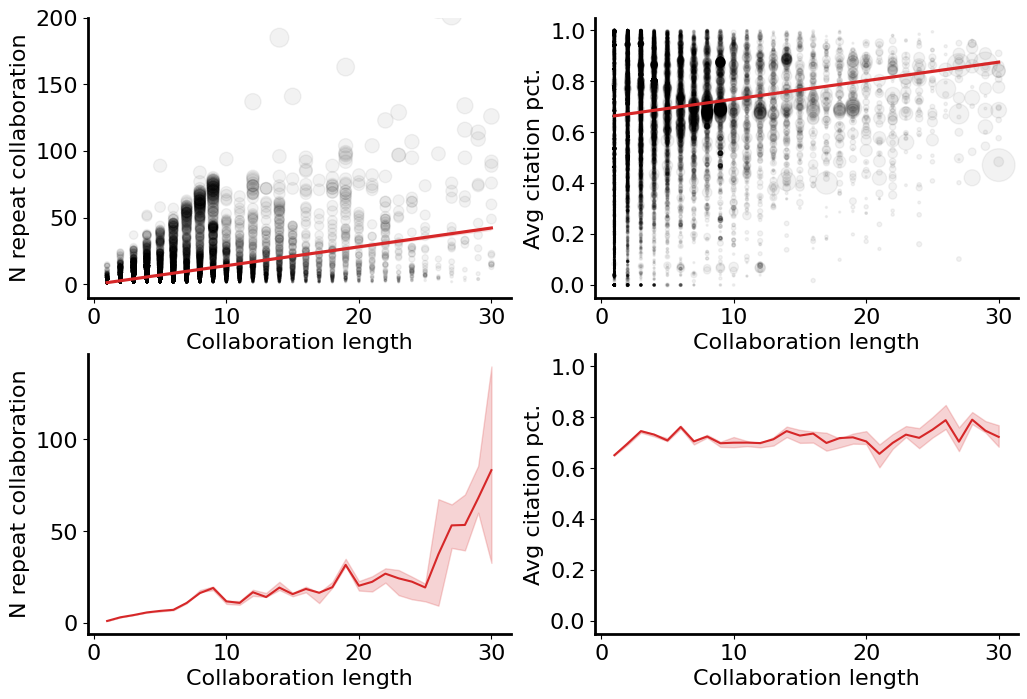

In [42]:
colors = sns.color_palette("icefire",5)
fig = plt.figure(figsize=(12 , 8))
gs = gridspec.GridSpec(2, 2, figure=fig)
ax = fig.add_subplot(gs[0])
plt.scatter(data['l'].values , data['k'].values , c = 'k' , alpha = .05 , s = data['k'].values)
sns.regplot(data , x='l' , y='k' , scatter=False , color = 'tab:red' , n_boot=5)
plt.ylim(-10,200)
set_fig_(ax , xlabel='$l$', ylabel='N k collaboration', xlog=0, ylog=0)

ax = fig.add_subplot(gs[1])
plt.scatter(data['l'].values , data['cit_pct'].values , c = 'k' , alpha = .05 , s = data['k'].values)
sns.regplot(data , x='l' , y='cit_pct' , scatter=False , color = 'tab:red' , n_boot=5)
set_fig_(ax , xlabel='$l$', ylabel='Avg citation pct.', xlog=0, ylog=0)

ax = fig.add_subplot(gs[2])
sns.lineplot(data , x='l' , y='k' , color = 'tab:red' , n_boot=5)
set_fig_(ax , xlabel='$l$', ylabel='N k collaboration', xlog=0, ylog=0)

ax = fig.add_subplot(gs[3])
sns.lineplot(data , x='l' , y='cit_pct' , color = 'tab:red' , n_boot=5)
plt.ylim(-0.05,1.05)
set_fig_(ax , xlabel='$l$', ylabel='Avg citation pct.', xlog=0, ylog=0)

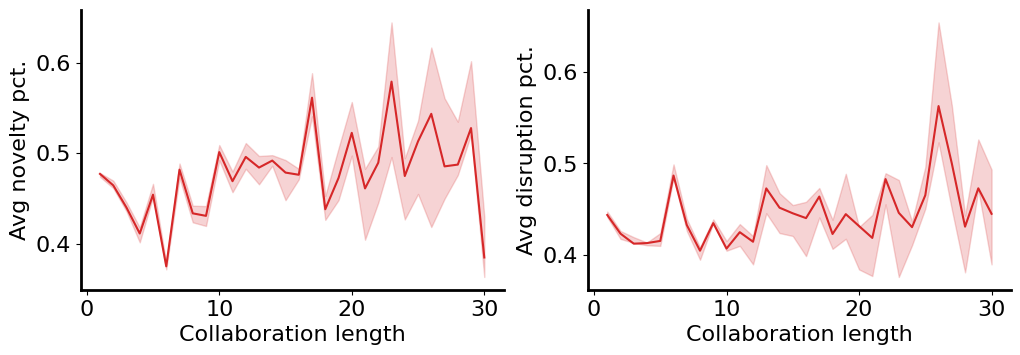

In [45]:
colors = sns.color_palette("icefire",5)
fig = plt.figure(figsize=(12 , 8))
gs = gridspec.GridSpec(2, 2, figure=fig)
ax = fig.add_subplot(gs[0])
sns.lineplot(data , x='l' , y='Novelty_pct' , color = 'tab:red' , n_boot=5)
set_fig_(ax , xlabel='$l$', ylabel='Avg novelty pct.', xlog=0, ylog=0)

ax = fig.add_subplot(gs[1])
sns.lineplot(data , x='l' , y='CD_pct' , color = 'tab:red' , n_boot=5)
set_fig_(ax , xlabel='$l$', ylabel='Avg disruption pct.', xlog=0, ylog=0)